Dataset:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape: (768, 9)

--- Simple Linear Regression ---
Intercept: 96.0442684599187
Coefficient: 0.7539628391789122
R2 Score: 0.0525531542583737
RMSE: 30.877569174785858

--- Multiple Linear Regression ---
Intercept: 86.07237091165987
Coefficients: [-0.13535301  0.17220972  0.70912422]
R2 S

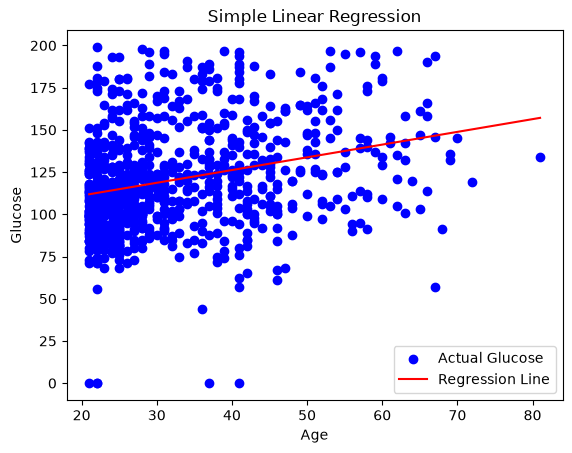

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
df = pd.read_csv(url)

print("Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)

X_simple = df[["Age"]]

X_multiple = df[["Pregnancies", "BloodPressure", "Age"]]


y = df["Glucose"]

X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, simple_predictions)
))

multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))

new_sample_simple = pd.DataFrame({
    "Age": [30]
})

new_sample_multiple = pd.DataFrame({
    "Pregnancies": [2],
    "BloodPressure": [70],
    "Age": [30]
})

print(
    "\nPredicted Glucose using Simple Regression:",
    simple_model.predict(new_sample_simple)[0]
)

print(
    "Predicted Glucose using Multiple Regression:",
    multiple_model.predict(new_sample_multiple)[0]
)

plt.scatter(
    df["Age"],
    df["Glucose"],
    color="blue",
    label="Actual Glucose"
)

plot_data = df[["Age"]].sort_values(by="Age")

plt.plot(
    plot_data["Age"],
    simple_model.predict(plot_data),
    color="red",
    label="Regression Line"
)

plt.xlabel("Age")
plt.ylabel("Glucose")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()